In [40]:
from dotenv import load_dotenv
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain.tools import tool
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.messages import ToolMessage, HumanMessage

load_dotenv()

llm = ChatGoogleGenerativeAI(model="gemini-2.5-flash")

In [41]:
from langchain_community.tools import DuckDuckGoSearchRun

@tool
def search_duckduckgo(query: str) -> str:

    """This tool searches the latest news on DuckDuckGo for the given query and returns the results."""
    duck_search = DuckDuckGoSearchRun()
    return duck_search.invoke(query)

In [42]:
from langchain_community.tools import ArxivQueryRun
from langchain_community.utilities import ArxivAPIWrapper

@tool
def arxiv_tool(query: str) -> str:

    """"This tool allows you to query the arXiv database for research papers."""
    arxiv_query = ArxivQueryRun(api_wrapper=ArxivAPIWrapper())
    return arxiv_query.invoke(query)

In [43]:
@tool
def personal_info(name: str) -> str:
    """Use this tool to get personal information about Alice, Bob, or Charlie."""

    info = {
        "Alice": "Alice is a software engineer with 5 years of experience in AI.",
        "Bob": "Bob is a data scientist who loves working with large datasets.",
        "Charlie": "Charlie is a product manager with a background in tech startups.",
    }
    return info.get(name, f"No information available for '{name}'.")

In [44]:
tools = [search_duckduckgo, arxiv_tool, personal_info]

llm_with_tools = llm.bind_tools(tools)

## What is a ReAct agent?

ReAct means **Reason + Act**.

- **Reasoning** is the model figuring out what the question needs and choosing a next step. For example, it may decide that it needs to search for current information.
- **Acting** is carrying out that step, usually by calling a tool. For example, the agent runs the web search tool and gets results back.

The model then reasons about the results and decides whether to use another tool or answer the user.

#### Create Schema

In [45]:
from typing import TypedDict, List

class graph_schema(TypedDict):
    messages: List

#### Create Node Functions

In [46]:
def llm_node(state: graph_schema) -> graph_schema:

    messages = state['messages']

    prompt = ChatPromptTemplate.from_messages([
        ("system", "You are a helpful assistant that can use tools to answer questions."),
        ("human", "{input}")
    ])

    chain = prompt | llm_with_tools

    response = chain.invoke({"input": messages})

    state["messages"] = messages + [response]

    return state

In [47]:
def tool_node(state: graph_schema) -> graph_schema:

    messages = state['messages']

    tools_by_name = {tool.name: tool for tool in tools}

    tool_results = []

    for tool_call in messages[-1].tool_calls:
        tool = tools_by_name[tool_call["name"]]
        observation = tool.invoke(tool_call["args"])
        tool_results.append(ToolMessage(content=observation, tool_call_id=tool_call["id"]))

    state["messages"] = messages + tool_results

    return state

#### Create Conditional Edge Function

In [48]:
def if_tool_call(state: graph_schema) -> str:

    last_message = state['messages'][-1]

    if last_message.tool_calls:
        return "tool_node"
    else:
        return "end"

#### Create State Graph

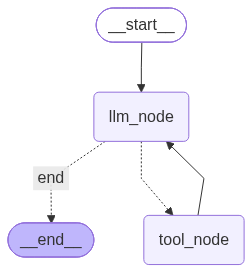

In [49]:
from langgraph.graph import StateGraph, START, END

graph = StateGraph(graph_schema)

graph.add_node("llm_node", llm_node)
graph.add_node("tool_node", tool_node)

graph.add_edge(START, "llm_node")
graph.add_conditional_edges("llm_node", if_tool_call, {"tool_node": "tool_node", "end": END})
graph.add_edge("tool_node", "llm_node")
graph.add_edge("llm_node", END)

react_graph = graph.compile()

from IPython.display import Image, display

# You could see the errors with the below command
Image(react_graph.get_graph().draw_mermaid_png())

In [53]:
react_graph.invoke({"messages": [HumanMessage(content="Give me the current captain of the Sri Lanka cricket team.")]})

{'messages': [HumanMessage(content='Give me the current captain of the Sri Lanka cricket team.', additional_kwargs={}, response_metadata={}),
  AIMessage(content='', additional_kwargs={'function_call': {'name': 'search_duckduckgo', 'arguments': '{"query": "current captain of Sri Lanka cricket team"}'}, '__gemini_function_call_thought_signatures__': {'48d844d8-a3af-45fb-97a9-6bf26ace2da2': 'CosDAWkUfRM8I204kJVnB/SSaAX4Ob1KA1orvGp9LsH8ZDt2vspWaxJZOwkEmZlGkMhvQG9AZxfvhoVTTNwYPwiNRd/k/+EbitAi8XiSpB4qjb6AifnnWJQo0u3KOYQHGUk2tIWMvnFac32PQec002ndmDRzwXDyAWURnJE4+fdAKV/O6rr8ocZ7LM5nV10Z5GmTTy3j5laFQkK2j7pWl03sUUzndV2U1oLx0hmi8zwGU1+hIT9dJqfsDiLDgXzv/FKpCVJ6PE4qrvEoMD5ssPu84qF9SIZmWXYfQ0BO/i6MOGYpKDNTXeHg79cT7Ii6b6NdeY0iKamKcrrRvHITu3RjnQq0NP5nxUHf/L9F7z8MtAlOnlneaHJcaCGycpE+eXBh3rnCE0/Ck2p+1E+hswPTSu4PRJAA8mPve0O0Yjz+XQoGOvOdkA4/WuNl6DX9aCfTUZxU4lTsbpCa7h5QI3qaJyfVsaPgHzu83NYVSYTWnMXlRa17gQBRuKAZWkzFlYhSyoRNSrAmeg8dtvY='}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-2.5-